# Bài tập Agent 01 — Q-Learning Agent điều hướng mê cung
Nguyễn Duy Nghĩa · B23DCCN600 · Nhóm lớp CT — Nhóm 07

Tác tử học tăng cường tự khám phá mê cung 12×12, tránh tường lửa và tìm đường ngắn nhất từ **S** về **G**.

## 1. Thư viện

In [1]:
import json
import time
from collections import deque
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

plt.rcParams.update({"font.size": 12, "figure.dpi": 110})

## 2. Môi trường mê cung (MDP: S, A, P, R)

In [2]:
# Mê cung 12 x 12: S xuất phát, G đích, # ô tường lửa (Fire), . ô trống
LAYOUT = [
    "S..#.....#..",
    ".#.#.###.#..",
    ".#...#.....#",
    ".###.#.###..",
    "...#...#....",
    "##.###.#.##.",
    "....#..#..#.",
    ".##.#.##.##.",
    "...#.....#..",
    "##.#.##.##.#",
    "....#.#.....",
    ".##...#.##.G",
]

# Bốn hành động rời rạc: (tên, dịch chuyển hàng, dịch chuyển cột)
ACTIONS = [("Trái", 0, -1), ("Phải", 0, 1), ("Lên", -1, 0), ("Xuống", 1, 0)]

R_FIRE = -10.0   # đâm vào tường lửa hoặc ra khỏi mê cung: bị phạt và đứng yên
R_GOAL = +100.0  # về đích: kết thúc episode
R_STEP = -1.0    # mỗi bước đi hợp lệ: phạt nhẹ để tác tử chọn đường ngắn


class MazeEnv:
    """Môi trường mê cung lưới: trạng thái là tọa độ (r, c), 4 hành động, phần thưởng theo ô đích đến."""

    def __init__(self, layout=LAYOUT):
        self.grid = np.array([list(row) for row in layout])
        self.n_rows, self.n_cols = self.grid.shape
        self.start = tuple(int(v) for v in np.argwhere(self.grid == "S")[0])
        self.goal = tuple(int(v) for v in np.argwhere(self.grid == "G")[0])
        self.n_states = self.n_rows * self.n_cols
        self.n_actions = len(ACTIONS)
        self.state = self.start

    def is_fire(self, r, c):
        return self.grid[r, c] == "#"

    def to_index(self, state):
        return state[0] * self.n_cols + state[1]

    def reset(self):
        self.state = self.start
        return self.state

    def step(self, action):
        """Thực hiện hành động; trả về (trạng thái mới, phần thưởng, kết thúc?)."""
        _, dr, dc = ACTIONS[action]
        r, c = self.state[0] + dr, self.state[1] + dc
        if not (0 <= r < self.n_rows and 0 <= c < self.n_cols) or self.is_fire(r, c):
            return self.state, R_FIRE, False
        self.state = (r, c)
        if self.state == self.goal:
            return self.state, R_GOAL, True
        return self.state, R_STEP, False

    def shortest_path_length(self):
        """BFS trên mê cung (tác tử không biết hàm này) để kiểm chứng lộ trình học được có ngắn nhất không."""
        dist = {self.start: 0}
        queue = deque([self.start])
        while queue:
            r, c = queue.popleft()
            for _, dr, dc in ACTIONS:
                nr, nc = r + dr, c + dc
                if 0 <= nr < self.n_rows and 0 <= nc < self.n_cols and not self.is_fire(nr, nc) \
                        and (nr, nc) not in dist:
                    dist[(nr, nc)] = dist[(r, c)] + 1
                    queue.append((nr, nc))
        return dist.get(self.goal)

## 3. Q-Learning Agent và vòng huấn luyện

In [3]:
# Siêu tham số của Q-Learning Agent
ALPHA = 0.1          # tốc độ học
GAMMA = 0.95         # hệ số chiết khấu
EPS_START = 1.0      # epsilon ban đầu: thăm dò hoàn toàn
EPS_MIN = 0.01       # epsilon tối thiểu
EPS_DECAY = 0.998    # epsilon nhân với hệ số này sau mỗi episode
EPISODES = 3000
MAX_STEPS = 300      # giới hạn bước mỗi episode (guardrail chống vòng lặp vô hạn)
LOG_EVERY = 250
SEED = 42


class QLearningAgent:
    """Learning Agent dạng bảng: Q-Table là tri thức, epsilon-greedy là Problem Generator,
    cập nhật Bellman là Learning Element."""

    def __init__(self, n_states, n_actions, alpha=ALPHA, gamma=GAMMA, epsilon=EPS_START, seed=SEED):
        self.q = np.zeros((n_states, n_actions))
        self.alpha, self.gamma, self.epsilon = alpha, gamma, epsilon
        self.n_actions = n_actions
        self.rng = np.random.default_rng(seed)

    def choose_action(self, s):
        """epsilon-greedy: thăm dò với xác suất epsilon, ngược lại khai thác argmax Q(s, a)."""
        if self.rng.random() < self.epsilon:
            return int(self.rng.integers(self.n_actions))
        best = np.flatnonzero(self.q[s] == self.q[s].max())
        return int(self.rng.choice(best))  # phá hòa ngẫu nhiên giữa các hành động bằng nhau

    def update(self, s, a, r, s_next, done):
        """Q(s,a) <- Q(s,a) + alpha * [r + gamma * max_a' Q(s',a') - Q(s,a)]"""
        target = r if done else r + self.gamma * self.q[s_next].max()
        self.q[s, a] += self.alpha * (target - self.q[s, a])

    def decay_epsilon(self):
        self.epsilon = max(EPS_MIN, self.epsilon * EPS_DECAY)


def train(env, agent, episodes=EPISODES, max_steps=MAX_STEPS, log_every=LOG_EVERY):
    """Huấn luyện qua nhiều episode; trả về lịch sử phần thưởng, số bước, epsilon, cờ về đích."""
    hist = {"reward": [], "steps": [], "epsilon": [], "success": []}
    t0 = time.perf_counter()
    for ep in range(1, episodes + 1):
        state, total, done = env.reset(), 0.0, False
        s = env.to_index(state)
        for step in range(1, max_steps + 1):
            a = agent.choose_action(s)
            state, r, done = env.step(a)
            s_next = env.to_index(state)
            agent.update(s, a, r, s_next, done)
            s, total = s_next, total + r
            if done:
                break
        hist["reward"].append(total)
        hist["steps"].append(step)
        hist["epsilon"].append(agent.epsilon)
        hist["success"].append(done)
        agent.decay_epsilon()
        if ep % log_every == 0:
            w = slice(ep - log_every, ep)
            print(f"Episode {ep:5d} | epsilon={hist['epsilon'][-1]:.3f} | "
                  f"thưởng TB={np.mean(hist['reward'][w]):8.2f} | bước TB={np.mean(hist['steps'][w]):6.1f} | "
                  f"về đích={100 * np.mean(hist['success'][w]):5.1f}%")
    hist["seconds"] = time.perf_counter() - t0
    return hist


def greedy_path(env, agent, max_steps=MAX_STEPS):
    """Chạy chính sách tham lam pi*(s) = argmax_a Q(s, a) từ S; trả về lộ trình và tổng phần thưởng."""
    state, total, path = env.reset(), 0.0, [env.start]
    for _ in range(max_steps):
        a = int(np.argmax(agent.q[env.to_index(state)]))
        state, r, done = env.step(a)
        total += r
        path.append(state)
        if done:
            break
    return path, total

## 4. Huấn luyện tác tử

In [4]:
env = MazeEnv()
agent = QLearningAgent(env.n_states, env.n_actions)
print(f"Mê cung {env.n_rows}x{env.n_cols}: {env.n_states} trạng thái, {int((env.grid == '#').sum())} ô tường lửa, "
      f"S={env.start}, G={env.goal}")
print(f"alpha={ALPHA}, gamma={GAMMA}, epsilon: {EPS_START} -> {EPS_MIN} (x{EPS_DECAY}/episode), "
      f"{EPISODES} episodes, tối đa {MAX_STEPS} bước/episode")
hist = train(env, agent)
print(f"Huấn luyện xong trong {hist['seconds']:.2f} giây")

Mê cung 12x12: 144 trạng thái, 55 ô tường lửa, S=(0, 0), G=(11, 11)
alpha=0.1, gamma=0.95, epsilon: 1.0 -> 0.01 (x0.998/episode), 3000 episodes, tối đa 300 bước/episode


Episode   250 | epsilon=0.607 | thưởng TB= -783.52 | bước TB= 185.4 | về đích= 61.6%
Episode   500 | epsilon=0.368 | thưởng TB=  -38.54 | bước TB=  48.7 | về đích=100.0%


Episode   750 | epsilon=0.223 | thưởng TB=   26.85 | bước TB=  34.7 | về đích=100.0%
Episode  1000 | epsilon=0.135 | thưởng TB=   50.51 | bước TB=  29.7 | về đích=100.0%


Episode  1250 | epsilon=0.082 | thưởng TB=   62.76 | bước TB=  26.9 | về đích=100.0%
Episode  1500 | epsilon=0.050 | thưởng TB=   68.76 | bước TB=  25.7 | về đích=100.0%


Episode  1750 | epsilon=0.030 | thưởng TB=   71.50 | bước TB=  25.2 | về đích=100.0%
Episode  2000 | epsilon=0.018 | thưởng TB=   74.09 | bước TB=  24.6 | về đích=100.0%


Episode  2250 | epsilon=0.011 | thưởng TB=   74.95 | bước TB=  24.5 | về đích=100.0%
Episode  2500 | epsilon=0.010 | thưởng TB=   75.36 | bước TB=  24.3 | về đích=100.0%


Episode  2750 | epsilon=0.010 | thưởng TB=   76.02 | bước TB=  24.3 | về đích=100.0%
Episode  3000 | epsilon=0.010 | thưởng TB=   76.24 | bước TB=  24.3 | về đích=100.0%
Huấn luyện xong trong 2.39 giây


## 5. Lộ trình tối ưu theo chính sách tham lam

In [5]:
path, total = greedy_path(env, agent)
print(f"Lộ trình học được: {len(path) - 1} bước, tổng phần thưởng {total:+.1f}")
print(f"Đường ngắn nhất (BFS kiểm chứng): {env.shortest_path_length()} bước")
print(" -> ".join(str(p) for p in path))

Lộ trình học được: 24 bước, tổng phần thưởng +77.0
Đường ngắn nhất (BFS kiểm chứng): 24 bước
(0, 0) -> (0, 1) -> (0, 2) -> (1, 2) -> (2, 2) -> (2, 3) -> (2, 4) -> (3, 4) -> (4, 4) -> (4, 5) -> (4, 6) -> (5, 6) -> (6, 6) -> (6, 5) -> (7, 5) -> (8, 5) -> (8, 6) -> (8, 7) -> (9, 7) -> (10, 7) -> (10, 8) -> (10, 9) -> (10, 10) -> (11, 10) -> (11, 11)


## 6. Trực quan hóa kết quả

In [6]:
ACTION_NAMES = ["Trái", "Phải", "Lên", "Xuống"]


def draw_maze(ax, env, path):
    """Vẽ mê cung (tường lửa đỏ cam), lộ trình tối ưu (đường xanh) và hai ô S, G."""
    walls = (env.grid == "#").astype(int)
    ax.imshow(walls, cmap=ListedColormap(["#F8FAFC", "#EA580C"]), vmin=0, vmax=1)
    ys, xs = zip(*path)
    ax.plot(xs, ys, color="#2563EB", lw=4, marker="o", ms=5, label=f"Lộ trình tối ưu ({len(path) - 1} bước)")
    ax.text(*env.start[::-1], "S", ha="center", va="center", fontsize=15, weight="bold", color="#15803D")
    ax.text(*env.goal[::-1], "G", ha="center", va="center", fontsize=15, weight="bold", color="#7C3AED")
    ax.set_xticks(np.arange(-0.5, env.n_cols, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, env.n_rows, 1), minor=True)
    ax.grid(which="minor", color="#94A3B8", lw=0.8)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="minor", length=0)
    ax.set_xticks(range(env.n_cols))
    ax.set_yticks(range(env.n_rows))
    ax.set_title(f"Mê cung {env.n_rows}×{env.n_cols}: lộ trình của tác tử")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), frameon=False)


def draw_rewards(ax, hist, window=100):
    """Phần thưởng mỗi episode, trung bình trượt và epsilon (trục phải)."""
    rewards = np.array(hist["reward"])
    ma = np.convolve(rewards, np.ones(window) / window, mode="valid")
    ep = np.arange(1, len(rewards) + 1)
    ax.plot(ep, rewards, color="#93C5FD", lw=0.8, alpha=0.7, label="Phần thưởng mỗi episode")
    ax.plot(ep[window - 1:], ma, color="#1D4ED8", lw=2.6, label=f"Trung bình trượt {window} episode")
    ax.set_ylim(max(rewards.min(), -400), rewards.max() + 20)
    ax.set_xlabel("Episode")
    ax.set_ylabel("Tổng phần thưởng")
    ax.set_title("Đường cong hội tụ phần thưởng")
    ax2 = ax.twinx()
    ax2.plot(ep, hist["epsilon"], color="#DC2626", lw=2, ls="--", label="epsilon")
    ax2.set_ylabel("epsilon", color="#DC2626")
    ax2.set_ylim(0, 1.05)
    lines = ax.get_lines() + ax2.get_lines()
    ax.legend(lines, [l.get_label() for l in lines], loc="lower right")


def q_table_excerpt(env, agent, path):
    """Trích Q-Table tại các ô then chốt: xuất phát, các điểm rẽ của lộ trình và ô ngay trước đích."""
    keys = [path[0]]
    for prev, cur, nxt in zip(path, path[1:], path[2:]):
        if (cur[0] - prev[0], cur[1] - prev[1]) != (nxt[0] - cur[0], nxt[1] - cur[1]):
            keys.append(cur)
    keys.append(path[-2])
    rows = []
    for s in dict.fromkeys(keys):
        q = agent.q[env.to_index(s)]
        rows.append({"Trạng thái": str(s), **{f"Q({n})": round(float(v), 2) for n, v in zip(ACTION_NAMES, q)},
                     "π*(s)": ACTION_NAMES[int(np.argmax(q))]})
    return pd.DataFrame(rows)

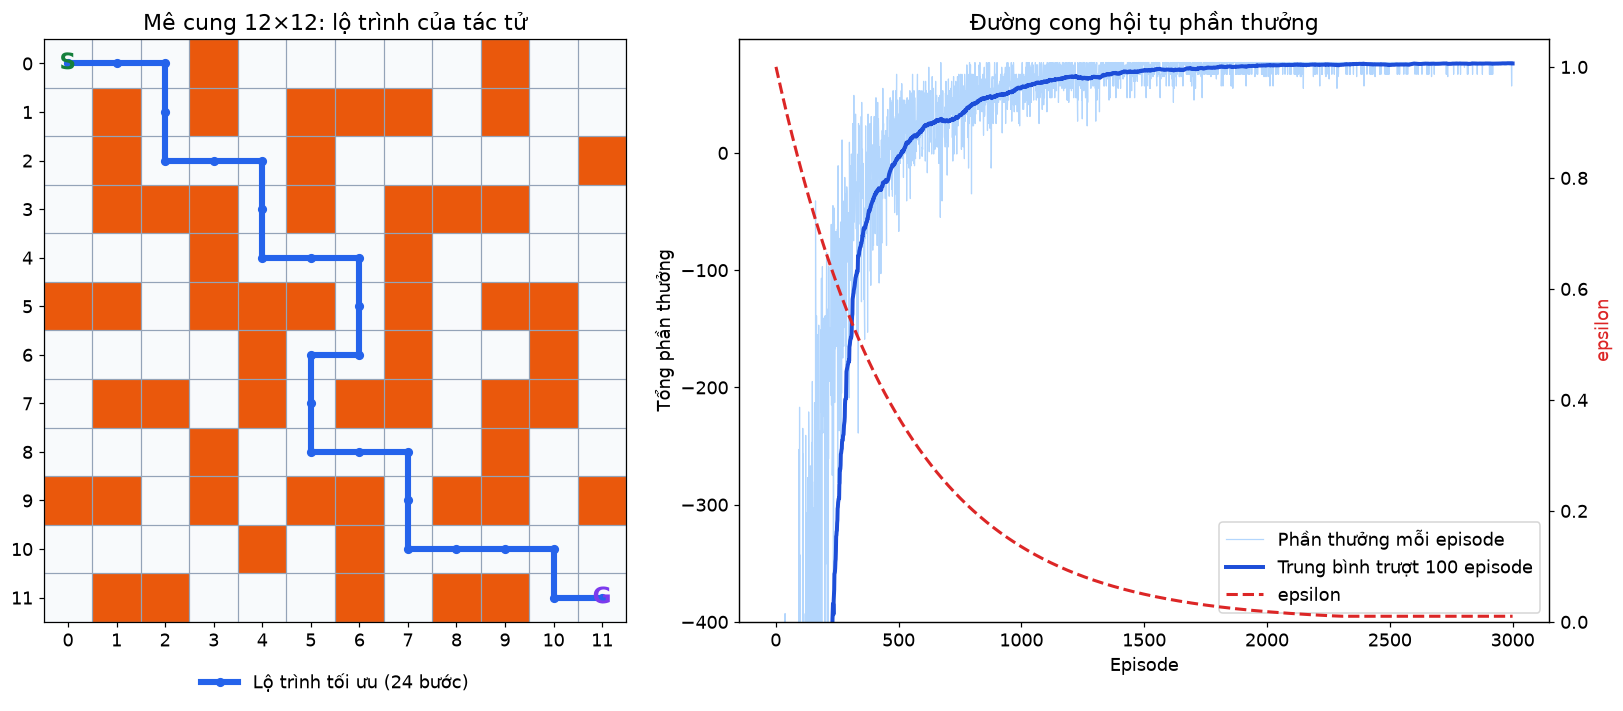

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.4), gridspec_kw={"width_ratios": [1, 1.35]})
draw_maze(ax1, env, path)
draw_rewards(ax2, hist)
fig.tight_layout()
plt.show()

## 7. Trích đoạn Q-Table tại các ô then chốt

In [8]:
qtab = q_table_excerpt(env, agent, path)
qtab

,Trạng thái,Q(Trái),Q(Phải),Q(Lên),Q(Xuống),π*(s)
0,"(0, 0)",6.04,16.88,6.04,13.28,Phải
1,"(0, 2)",16.88,9.82,9.82,20.87,Xuống
2,"(2, 2)",14.01,25.28,20.87,14.02,Phải
3,"(2, 4)",25.28,18.67,25.28,30.17,Xuống
4,"(4, 4)",23.81,35.59,30.17,23.81,Phải
5,"(4, 6)",35.59,29.52,35.59,41.60,Xuống
6,"(6, 6)",48.26,35.84,41.60,35.84,Trái
7,"(6, 5)",39.26,44.84,39.26,51.85,Xuống
8,"(8, 5)",51.85,59.61,51.85,46.63,Phải
9,"(8, 7)",59.61,59.61,54.80,68.21,Xuống


## 8. Lưu số liệu cho báo cáo

In [9]:
def first_episode(cond):
    return next((i + 1 for i, ok in enumerate(cond) if ok), None)

rewards = np.array(hist["reward"])
ma = np.convolve(rewards, np.ones(100) / 100, mode="valid")
metrics = {
    "params": {"alpha": ALPHA, "gamma": GAMMA, "eps_start": EPS_START, "eps_min": EPS_MIN, "eps_decay": EPS_DECAY,
               "episodes": EPISODES, "max_steps": MAX_STEPS, "r_fire": R_FIRE, "r_goal": R_GOAL, "r_step": R_STEP,
               "n_rows": env.n_rows, "n_cols": env.n_cols, "n_states": env.n_states,
               "n_fire": int((env.grid == "#").sum()), "start": str(env.start), "goal": str(env.goal)},
    "result": {"path_len": len(path) - 1, "bfs_len": env.shortest_path_length(), "greedy_reward": total,
               "seconds": hist["seconds"], "first_success": first_episode(hist["success"]),
               "ma_first_positive": first_episode(ma > 0) + 99,
               "eps_below_005": first_episode(np.array(hist["epsilon"]) < 0.05),
               "reward_first100": rewards[:100].mean(), "reward_min": rewards.min(),
               "reward_last100": rewards[-100:].mean(), "steps_last100": np.mean(hist["steps"][-100:]),
               "success_first250": np.mean(hist["success"][:250]), "success_last100": np.mean(hist["success"][-100:])},
    "qtable": qtab.to_dict(orient="records"),
    "history": {k: hist[k] for k in ("reward", "steps", "epsilon", "success")},
    "path": [list(p) for p in path],
}
out = Path("../outputs/metrics/ch8_qlearning.json")
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(metrics, ensure_ascii=False, indent=1, default=lambda o: o.item()), encoding="utf-8")
print("Đã ghi", out, "-", {k: metrics["result"][k] for k in ("path_len", "bfs_len", "greedy_reward")})

Đã ghi ..\outputs\metrics\ch8_qlearning.json - {'path_len': 24, 'bfs_len': 24, 'greedy_reward': 77.0}
